<a href="https://colab.research.google.com/github/seanyi-creator/ba-305-project/blob/main/04_neural_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Workstream 3 — Neural network
**Question:** When a building permit is filed in San Francisco, can its project details (type, cost, unit and story changes, location, …) predict whether the project will be abandoned rather than completed?

**Who acts on it:** SF's Department of Building Inspection and Planning, by flagging high-risk permits at filing and pointing applicants to extensions or fee deferrals.

Logistic regression (`02`) can only draw straight-line boundaries. The tree and forest (`03`) capture bends and interactions with yes/no rules. A **neural network** is a third way to capture non-linear patterns: smooth curves learned from the data. This notebook asks whether that buys anything over the random forest.

| Step | What it does |
|---|---|
| 1 | What a neural network is, and the design choices we make up front |
| 2 | Why the inputs must be scaled (a quick experiment) |
| 3 | Watching a network overfit, epoch by epoch |
| 4 | The two brakes: weight decay (`alpha`) and early stopping |
| 5 | **Hyperparameter tuning, round 1:** network size × `alpha` |
| 6 | **Hyperparameter tuning, round 2:** learning rate × batch size |
| 7 | How much does the random starting point matter? |
| 8 | **Test-set results** against the baselines, logistic regression, the tree and the forest |
| 9 | Using it: flagging the riskiest permits |
| 10 | What drives the network |
| 11 | **Conclusions and design choices recap** |

⏱ **Runtime:** about 5 minutes on a laptop, roughly 10–15 minutes on free Colab (mostly the tuning in Steps 5–7).

> **Label reminder:** as in `02` and `03`, **`y = 1` means the permit did *not* finish** (expired, cancelled, withdrawn, disapproved, revoked or denied), so recall means "share of failing permits caught".

In [1]:
# --- setup ---
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
                             RocCurveDisplay)
warnings.filterwarnings('ignore', category=ConvergenceWarning)   # explained in Step 3
pd.set_option('display.max_columns', 50)

## Shared data (copied unchanged from `02_logistic.ipynb`)
Same rows, features, grouped train/test split and preprocessor as the other models, so all results are comparable.

In [2]:
# --- Sean: SHARED CELL — load, target, filing-year filter, leakage drops, features, split, preprocessor ---
# Copy this whole cell into your notebook, then run:
#   X_train, X_test, y_train, y_test, groups_train, preprocessor = get_permit_data()
# and cross-validate with cv=make_cv() and .fit(X_train, y_train, groups=groups_train)
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PERMITS_URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2022/2022-07-05/sf_permits.csv"

# Statuses where the outcome is final. 'complete' = 0; every other final status = 1 (did not finish).
FINAL_STATUS = {'complete': 0, 'expired': 1, 'cancelled': 1, 'withdrawn': 1,
                'disapproved': 1, 'revoked': 1, 'denied': 1}
YEAR_MIN, YEAR_MAX = 2000, 2013   # filing years kept (see Step 2)
RANDOM_STATE = 42                 # everyone uses this, so the split is identical

# Columns recorded AFTER filing (leak the outcome) or that are only labels for a case (see Step 3).
LEAKAGE_COLS = ['status', 'status_date', 'completed_date', 'issued_date', 'permit_expiration_date',
                'first_construction_document_date', 'revised_cost']
ID_COLS = ['permit_number', 'record_id', 'block', 'lot', 'street_number', 'street_number_suffix',
           'street_name', 'street_suffix', 'unit', 'unit_suffix', 'location', 'description',
           'permit_creation_date', 'filed_date', 'date', 'zipcode', 'tidf_compliance',
           'permit_type', 'existing_construction_type', 'proposed_construction_type']
# description: free text, left out of the baseline feature set (an optional extension).
# zipcode: overlaps with neighborhood; permit_type / construction_type codes: duplicates of their text labels.
# tidf_compliance: 100% missing.

NUMERIC = ['log_estimated_cost', 'cost_is_placeholder', 'plansets',
           'existing_units', 'proposed_units', 'unit_change',
           'number_of_existing_stories', 'number_of_proposed_stories', 'story_change',
           'filing_year', 'filing_month']
CATEGORICAL = ['permit_type_definition', 'existing_use', 'proposed_use', 'use_changes',
               'existing_construction_type_description', 'proposed_construction_type_description',
               'structural_notification', 'site_permit', 'fire_only_permit',
               'voluntary_soft_story_retrofit', 'neighborhoods_analysis_boundaries',
               'supervisor_district']


def load_permits(url=PERMITS_URL):
    """Raw file, as downloaded."""
    return pd.read_csv(url, low_memory=False)


def resolved_permits(raw):
    """Keep permits with a final outcome, filed in YEAR_MIN..YEAR_MAX, and add the target y."""
    df = raw[raw['status'].isin(FINAL_STATUS)].copy()
    df['filed'] = pd.to_datetime(df['filed_date'])
    df = df[df['filed'].dt.year.between(YEAR_MIN, YEAR_MAX)]
    df['y'] = df['status'].map(FINAL_STATUS)          # 1 = did not finish
    return df


def add_features(df):
    """Features that are all known on the day the permit is filed."""
    out = df.copy()
    cost = out['estimated_cost']
    out['cost_is_placeholder'] = (cost <= 1).astype(int)          # $0/$1 entered as a placeholder
    out['log_estimated_cost'] = np.log10(cost.where(cost > 1))     # skewed: $1 to $500M+, so use log10
    out['unit_change'] = out['proposed_units'] - out['existing_units']
    out['story_change'] = out['number_of_proposed_stories'] - out['number_of_existing_stories']
    both_known = out['existing_use'].notna() & out['proposed_use'].notna()
    out['use_changes'] = (out['existing_use'] != out['proposed_use']).map({True: 'yes', False: 'no'}).where(both_known)
    out['filing_year'] = out['filed'].dt.year
    out['filing_month'] = out['filed'].dt.month
    out['supervisor_district'] = out['supervisor_district'].astype('Int64').astype(str).replace('<NA>', np.nan)
    for c in ['structural_notification', 'site_permit', 'fire_only_permit', 'voluntary_soft_story_retrofit']:
        out[c] = out[c].fillna('N')                                # blank means "not flagged"
    return out


def make_preprocessor():
    """Fit inside a Pipeline, so imputation and scaling learn from training folds only."""
    numeric = Pipeline([
        ('impute', SimpleImputer(strategy='median', add_indicator=True)),  # median + a 'was missing' flag
        ('scale', StandardScaler()),
    ])
    categorical = Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50)),  # rare levels pooled
    ])
    return ColumnTransformer([('num', numeric, NUMERIC), ('cat', categorical, CATEGORICAL)])


def batch_id(df):
    """Permits filed for the same lot on the same day are one project's batch (see Step 5)."""
    return df['block'].astype(str) + '-' + df['lot'].astype(str) + '-' + df['filed_date'].astype(str)


def make_cv():
    """5-fold CV that keeps each batch inside one fold and keeps the class mix similar."""
    return StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def get_permit_data(raw=None, test_size=0.2):
    """One call for teammates: same rows, features, grouped split and preprocessor for everyone."""
    raw = load_permits() if raw is None else raw
    df = add_features(resolved_permits(raw)).reset_index(drop=True)
    X, y, groups = df[NUMERIC + CATEGORICAL], df['y'], batch_id(df)
    train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=test_size,
                                                 random_state=RANDOM_STATE).split(X, y, groups))
    return (X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx],
            groups.iloc[train_idx], make_preprocessor())

In [3]:
# --- load the shared split ---
X_train, X_test, y_train, y_test, groups_train, preprocessor = get_permit_data()
cv = make_cv()
print(f'Train: {len(X_train):,} permits · Test: {len(X_test):,} permits · did not finish: {y_train.mean():.1%}')

Train: 49,676 permits · Test: 12,472 permits · did not finish: 35.7%


## Step 1 — What a neural network is, and the choices we make up front
A **multi-layer perceptron (MLP)**, the classic neural network for tabular data, works in layers:

```
166 input columns  →  hidden layer(s) of "neurons"  →  1 output: P(did not finish)
(cost, units, uses…)   each neuron = weighted sum of      squashed to 0–1 by the
                       its inputs, then ReLU: max(0, z)    sigmoid function
```

- Each hidden **neuron** computes a weighted sum of its inputs and passes it through **ReLU**, max(0, z). That bend is what lets the network draw curved boundaries. Without it, the whole network collapses into one logistic regression.
- The **output** neuron applies the **sigmoid**, exactly as logistic regression does. In fact, *a network with no hidden layer is logistic regression*. The hidden layers are what's new.
- **Training** starts with small random weights. The network predicts a batch of permits, measures the error with **log-loss** (the same loss logistic regression minimises), and nudges every weight downhill (**backpropagation**). One pass over all training permits is an **epoch**.

**Design choices made up front, and why:**

| Choice | What we use | Why |
|---|---|---|
| Library | scikit-learn `MLPClassifier` | Plugs into the same `Pipeline`, grouped CV and `GridSearchCV` as the other models, so the comparison is exactly like-for-like. Keras/PyTorch add flexibility we don't need for 166 tabular columns. |
| Hidden activation | ReLU | The modern default: fast, and avoids the "vanishing gradient" that slows sigmoid/tanh networks. |
| Optimiser | Adam | Adapts the step size for each weight. It works well with little tuning, which matters when every setting has to be cross-validated. |
| Inputs | the shared preprocessor (standardized numbers, one-hot categories) | Networks need inputs on similar scales (tested in Step 2). |
| Class imbalance | no reweighting | `MLPClassifier` has no `class_weight`. AUC does not depend on it, and the flagging cutoff is chosen separately (Step 9). |
| Score | ROC AUC with grouped 5-fold CV | Same yardstick as `02` and `03`. |

In [4]:
# --- Step 1 — what the network actually sees ---
Xt = make_preprocessor().fit_transform(X_train)
print(f'Each permit becomes {Xt.shape[1]} input numbers '
      f'({len(NUMERIC)} numeric features + missing-value flags + one-hot category columns).')
for h in [(32,), (64, 32)]:
    sizes = [Xt.shape[1], *h, 1]
    n_weights = sum((a + 1) * b for a, b in zip(sizes[:-1], sizes[1:]))     # +1 = bias term
    print(f'A network with hidden layers {h} has {n_weights:,} weights to learn '
          f'(logistic regression has {Xt.shape[1] + 1}).')

Each permit becomes 166 input numbers (11 numeric features + missing-value flags + one-hot category columns).
A network with hidden layers (32,) has 5,377 weights to learn (logistic regression has 167).
A network with hidden layers (64, 32) has 12,801 weights to learn (logistic regression has 167).


**What this means:** logistic regression learns 167 numbers (one weight per input column plus an intercept). Even a small network with one hidden layer of 32 neurons learns **5,377**, and a two-layer one more than 12,000. That extra capacity is what lets a network find curved patterns and interactions, and it is also what lets it **memorise** the training permits. Most of this notebook is about using that capacity without overfitting.

## Step 2 — Why the inputs must be scaled
Before training, every weight starts small and gets nudged by the same size of step. If one input runs from 2000 to 2013 (`filing_year`) and another is 0 or 1 (a one-hot column), a single step size can't suit both: the big-valued input swamps the others, and training is slow and unstable. Standardizing (mean 0, standard deviation 1) puts every numeric input on the same footing.

Trees don't care about scale (they only compare a value with a threshold), so this mattered for logistic regression but not for `03`. For a network it matters a lot. The experiment below trains the same small network with and without scaling.

In [5]:
# --- Step 2 — same network, with and without standardized inputs ---
def make_unscaled_preprocessor():
    numeric = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True))])
    categorical = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='missing')),
                            ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50))])
    return ColumnTransformer([('num', numeric, NUMERIC), ('cat', categorical, CATEGORICAL)])

def mlp(**kw):
    """The network used throughout: ReLU + Adam, early stopping on, fixed seed."""
    params = dict(hidden_layer_sizes=(32,), early_stopping=True, n_iter_no_change=10, max_iter=300,
                  random_state=RANDOM_STATE)
    params.update(kw)
    return MLPClassifier(**params)

rows = []
for name, prep in [('standardized (shared preprocessor)', make_preprocessor()),
                   ('raw numbers (no scaling)', make_unscaled_preprocessor())]:
    r = cross_validate(Pipeline([('prep', prep), ('model', mlp())]), X_train, y_train,
                       groups=groups_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    rows.append({'inputs': name, 'CV AUC': r['test_score'].mean(), 'CV AUC (sd)': r['test_score'].std()})
pd.DataFrame(rows).set_index('inputs').round(4)

,CV AUC,CV AUC (sd)
inputs,,
standardized (shared preprocessor),0.6624,0.0077
raw numbers (no scaling),0.6027,0.0096


**Result:** the identical network scores **0.662** CV AUC with standardized inputs and only **0.603** on raw numbers, a drop of 0.06, about as much as separates the random forest from logistic regression. On raw numbers, `filing_year` (≈ 2000–2013) and `log_estimated_cost` (≈ 2–9) dwarf the 0/1 columns, and training never settles properly.

**Design choice:** keep the shared preprocessor's standardization. It is also why this notebook can reuse the shared cell unchanged.

## Step 3 — Watching a network overfit, epoch by epoch
To see overfitting happen, we train a fairly large network (128 neurons) **one epoch at a time** with almost no regularization. After each epoch we score it on its own training permits and on a held-out validation fold (one grouped fold from the training set; the test set is still untouched).

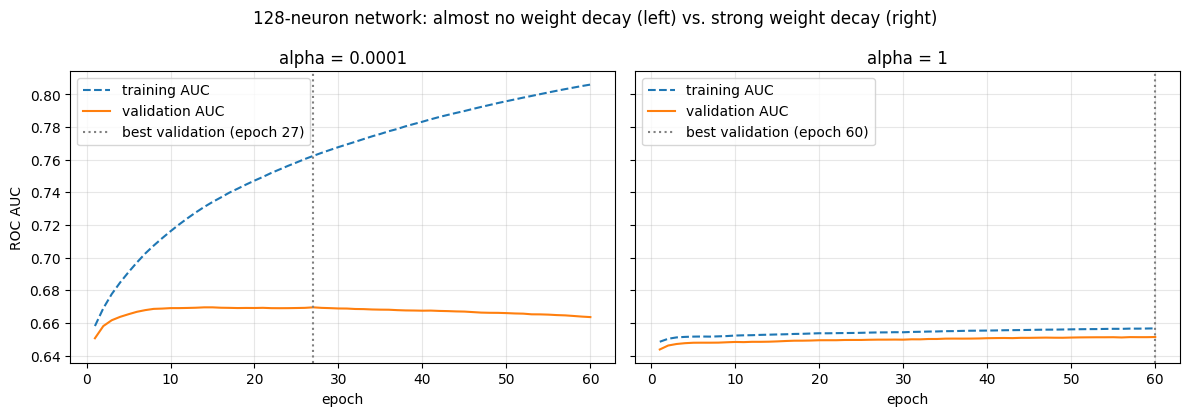

,alpha = 0.0001,alpha = 1
best validation AUC,0.6696,0.6514
at epoch,27.0000,60.0000
validation AUC after 60 epochs,0.6636,0.6514
training AUC after 60 epochs,0.8060,0.6567


In [6]:
# --- Step 3 — training vs validation AUC after every epoch ---
fit_idx, val_idx = next(cv.split(X_train, y_train, groups_train))
prep3 = make_preprocessor().fit(X_train.iloc[fit_idx])
Xf, Xv = prep3.transform(X_train.iloc[fit_idx]), prep3.transform(X_train.iloc[val_idx])
yf, yv = y_train.iloc[fit_idx].to_numpy(), y_train.iloc[val_idx].to_numpy()

def epoch_curve(alpha, epochs=60, hidden=(128,)):
    net = MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, random_state=RANDOM_STATE)
    tr, va = [], []
    for _ in range(epochs):
        net.partial_fit(Xf, yf, classes=[0, 1])                 # one more pass over the data
        tr.append(roc_auc_score(yf, net.predict_proba(Xf)[:, 1]))
        va.append(roc_auc_score(yv, net.predict_proba(Xv)[:, 1]))
    return np.array(tr), np.array(va)

curves = {a: epoch_curve(a) for a in [1e-4, 1.0]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (a, (tr, va)) in zip(axes, curves.items()):
    ep = np.arange(1, len(tr) + 1)
    ax.plot(ep, tr, '--', label='training AUC'); ax.plot(ep, va, label='validation AUC')
    ax.axvline(ep[va.argmax()], color='grey', ls=':', label=f'best validation (epoch {ep[va.argmax()]})')
    ax.set_title(f'alpha = {a:g}'); ax.set_xlabel('epoch'); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel('ROC AUC')
fig.suptitle('128-neuron network: almost no weight decay (left) vs. strong weight decay (right)')
plt.tight_layout(); plt.show()
pd.DataFrame({f'alpha = {a:g}': {'best validation AUC': va.max(), 'at epoch': int(va.argmax()) + 1,
                                  'validation AUC after 60 epochs': va[-1], 'training AUC after 60 epochs': tr[-1]}
              for a, (tr, va) in curves.items()}).round(4)

**Reading the curves:**
- **Left (alpha = 0.0001, almost no penalty):** validation AUC climbs fast and peaks at **0.670 around epoch 15–27**, then slowly *falls* (0.664 by epoch 60), while training AUC keeps climbing to 0.806. That widening gap is **overfitting in real time**: after about 20 epochs the extra training only memorises noise.
- **Right (alpha = 1, strong penalty):** training and validation stay glued together, but both are stuck around 0.65. The penalty is so strong the network can't learn the patterns it needs: **underfitting**.

**Takeaways that shape the rest of the notebook:**
1. **Stop training at the right epoch** (early stopping), because the best validation score comes long before the network stops improving on training data.
2. **Tune `alpha`** to sit between the two extremes.

## Step 4 — The two brakes: weight decay and early stopping
Step 3 shows the two tools that keep a network honest. Both are used from here on.

**1. Weight decay (`alpha`)** adds a penalty for large weights to the loss, exactly like `C` in logistic regression but the other way round: **larger `alpha` = stronger penalty = simpler network**. It is tuned in Step 5.

**2. Early stopping:** set aside 10% of the training rows inside each fit, check them after every epoch, and stop once they haven't improved for 10 epochs in a row (`n_iter_no_change=10`). The network keeps the weights from its best epoch. This picks the number of epochs automatically, so it doesn't need to be tuned.

**Why early stopping is on, and its small cost.** Without it, each network would train for a fixed number of epochs (too few: underfit; too many: overfit, as Step 3 shows), which would be one more hyperparameter to search. The cost: scikit-learn's internal 10% is a *random* sample of rows (not grouped by project batch) and it watches accuracy, not AUC. That makes the stopping point slightly noisy, but the hyperparameters are still *chosen* by grouped-CV AUC, so the comparison with other models stays fair.

*(The `ConvergenceWarning` silenced in the setup cell is scikit-learn saying a network hit `max_iter` before early stopping fired. With early stopping on, that rarely happens and is harmless.)*

## Step 5 — Tuning, round 1: network size × weight decay
These two hyperparameters set how complex the network can be, so they are tuned together:
- **`hidden_layer_sizes`**: the architecture. One hidden layer of 16, 32, 64 or 128 neurons, or two layers (32→16, 64→32). More neurons and layers mean more capacity to learn patterns, and more room to memorise noise.
- **`alpha`**: weight decay from 0.0001 (almost none) to 1 (strong), on a log scale, because its effect works in multiples.

6 architectures × 5 alphas = **30 combinations**, each scored by ROC AUC with grouped 5-fold CV on the training set. Everything else stays at the defaults from Step 2 (Adam, learning rate 0.001, batches of 200).

**Why a grid in two rounds, not everything at once?** A network has many knobs. Searching all of them together multiplies the combinations (6 × 5 × 4 × 2 = 240 × 5 folds), so we tune the knobs that control *complexity* first, then the knobs that control *how training moves* (round 2).

In [7]:
# --- Step 5 — round 1: architecture × alpha ---
def nn_pipe(**kw):
    return Pipeline([('prep', make_preprocessor()), ('model', mlp(**kw))])

grid1 = {'model__hidden_layer_sizes': [(16,), (32,), (64,), (128,), (32, 16), (64, 32)],
         'model__alpha': [1e-4, 1e-3, 1e-2, 1e-1, 1.0]}
t0 = time.time()
search1 = GridSearchCV(nn_pipe(), grid1, cv=cv, scoring='roc_auc', return_train_score=True, n_jobs=-1)
search1.fit(X_train, y_train, groups=groups_train)
res1 = pd.DataFrame(search1.cv_results_)
res1['architecture'] = res1['param_model__hidden_layer_sizes'].astype(str)
print(f'{len(res1)} combinations × 5 folds in {time.time() - t0:.0f}s')
print('Best:', search1.best_params_, '· CV AUC', round(search1.best_score_, 4))
order = [str(h) for h in grid1['model__hidden_layer_sizes']]
(res1.pivot_table(index='architecture', columns='param_model__alpha', values='mean_test_score')
     .loc[order].round(4).rename_axis(index='hidden layers', columns='alpha → (CV AUC)'))

30 combinations × 5 folds in 98s
Best: {'model__alpha': 0.1, 'model__hidden_layer_sizes': (64,)} · CV AUC 0.6657


alpha → (CV AUC),0.0001,0.0010,0.0100,0.1000,1.0000
hidden layers,,,,,
"(16,)",0.6570,0.6588,0.6599,0.6625,0.6485
"(32,)",0.6624,0.6618,0.6632,0.6618,0.6493
"(64,)",0.6610,0.6613,0.6611,0.6657,0.6476
"(128,)",0.6617,0.6612,0.6639,0.6656,0.6482
"(32, 16)",0.6610,0.6633,0.6618,0.6633,0.6505
"(64, 32)",0.6542,0.6595,0.6588,0.6630,0.6495


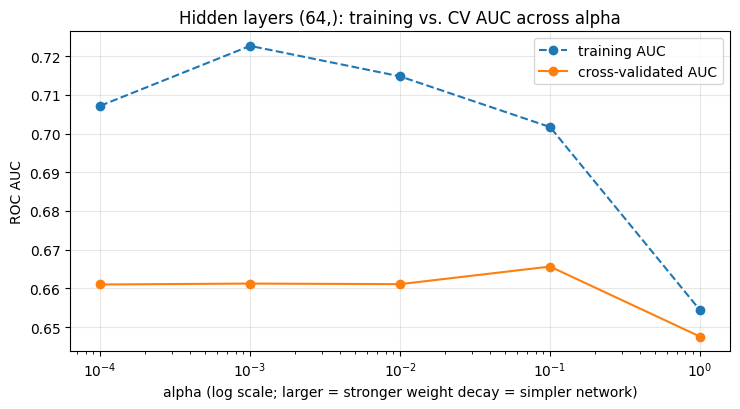

,training AUC,CV AUC,CV AUC (sd)
alpha,,,
0.0001,0.7071,0.6610,0.0030
0.0010,0.7226,0.6613,0.0043
0.0100,0.7148,0.6611,0.0031
0.1000,0.7017,0.6657,0.0051
1.0000,0.6544,0.6476,0.0052


In [8]:
# --- Step 5 — over/underfitting across alpha for the best architecture ---
best_arch = search1.best_params_['model__hidden_layer_sizes']
sub = res1[res1['architecture'] == str(best_arch)].sort_values('param_model__alpha')
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(sub['param_model__alpha'].astype(float), sub['mean_train_score'], '--o', label='training AUC')
ax.plot(sub['param_model__alpha'].astype(float), sub['mean_test_score'], '-o', label='cross-validated AUC')
ax.set_xscale('log'); ax.set_xlabel('alpha (log scale; larger = stronger weight decay = simpler network)')
ax.set_ylabel('ROC AUC'); ax.grid(alpha=0.3); ax.legend()
ax.set_title(f'Hidden layers {best_arch}: training vs. CV AUC across alpha')
plt.tight_layout(); plt.show()
sub[['param_model__alpha', 'mean_train_score', 'mean_test_score', 'std_test_score']].round(4) \
    .set_axis(['alpha', 'training AUC', 'CV AUC', 'CV AUC (sd)'], axis=1).set_index('alpha')

**Reading round 1:**
- **Best: one hidden layer of 64 neurons with `alpha = 0.1`, CV AUC 0.666.** (128 neurons at `alpha = 0.1` ties at 0.6656. 64 is kept because it is smaller and does the same job.)
- **`alpha` matters more than the architecture.** Down each column the scores barely move (≈ 0.66), but `alpha = 1` drags every architecture down to ≈ 0.65 (underfitting, as in Step 3).
- **The best value is inside the range,** not at an edge: `alpha = 1` is clearly worse and 0.0001–0.01 slightly worse, so the range was wide enough.
- **Bigger isn't better.** The largest network (64 → 32) is the weakest at low `alpha` (0.654): more weights, more memorising. A second layer adds nothing here.
- **The fit curve:** training AUC sits at 0.70–0.72 for small `alpha` against a CV AUC of 0.661, a gap of about 0.05, which is mild overfitting. At `alpha = 0.1` the gap narrows (0.702 vs. 0.666) and CV is highest. At `alpha = 1` the gap closes, but both scores drop (0.654 vs. 0.648): underfitting.

**Why one hidden layer is enough:** with 23 original features, most of the signal is a handful of strong effects (filing year, cost, size) with some bends and interactions. One layer of neurons can already represent any smooth curve of the inputs, and extra depth pays off mainly on raw data such as images or text, where features must be built up in stages.

## Step 6 — Tuning, round 2: learning rate × batch size
With the size and the penalty fixed at their round-1 best, we tune how training *moves*:
- **`learning_rate_init`**: the size of each step downhill. Too small and training crawls (early stopping may cut it off before it gets anywhere); too large and it overshoots and bounces around. Tried 0.0003, 0.001 (default), 0.003 and 0.01.
- **`batch_size`**: how many permits are used for each step. Small batches (64) mean many noisy steps per epoch, and the noise can help escape poor solutions. Large batches (256) mean fewer, smoother steps.

4 × 2 = **8 combinations**, same grouped 5-fold CV.

In [9]:
# --- Step 6 — round 2: learning rate × batch size at the round-1 best ---
best_alpha = search1.best_params_['model__alpha']
grid2 = {'model__learning_rate_init': [3e-4, 1e-3, 3e-3, 1e-2], 'model__batch_size': [64, 256]}
t0 = time.time()
search2 = GridSearchCV(nn_pipe(hidden_layer_sizes=best_arch, alpha=best_alpha), grid2, cv=cv,
                       scoring='roc_auc', return_train_score=True, n_jobs=-1)
search2.fit(X_train, y_train, groups=groups_train)
res2 = pd.DataFrame(search2.cv_results_)
NN_BEST = {'hidden_layer_sizes': best_arch, 'alpha': best_alpha,
           'learning_rate_init': search2.best_params_['model__learning_rate_init'],
           'batch_size': search2.best_params_['model__batch_size']}
print(f'{len(res2)} combinations × 5 folds in {time.time() - t0:.0f}s')
print('NN_BEST =', NN_BEST, '· CV AUC', round(search2.best_score_, 4))
(res2.pivot_table(index='param_model__learning_rate_init', columns='param_model__batch_size', values='mean_test_score')
     .round(4).rename_axis(index='learning rate', columns='batch size → (CV AUC)'))

8 combinations × 5 folds in 40s
NN_BEST = {'hidden_layer_sizes': (64,), 'alpha': 0.1, 'learning_rate_init': 0.001, 'batch_size': 256} · CV AUC 0.6657


batch size → (CV AUC),64,256
learning rate,,
0.0003,0.6627,0.6633
0.0010,0.6628,0.6657
0.0030,0.6554,0.6646
0.0100,0.6441,0.6608


**Reading round 2:**
- **Best: learning rate 0.001 with batches of 256, CV AUC 0.666,** essentially the defaults (0.001 and 200). Adam's defaults are well chosen, which is one reason we picked Adam.
- **Too large a learning rate hurts,** especially with small batches: 0.01 with batches of 64 drops to 0.644, because many big, noisy steps overshoot. Larger batches smooth each step, so they tolerate faster rates better.
- **Too small a rate is fine but not better** (0.663): training just takes more epochs to get to the same place.

**Final settings, `NN_BEST`:** one hidden layer of 64 ReLU neurons, `alpha = 0.1`, learning rate 0.001, batches of 256, Adam, with early stopping.

## Step 7 — How much does the random starting point matter?
A network starts from random weights, and early stopping draws a random 10% of rows, so two runs with different seeds give slightly different networks. Logistic regression has no such randomness, and the forest averages it away over 200 trees. To be honest about our network's score, we refit the tuned settings with 5 different seeds and look at the spread of CV AUC.

**Why it matters:** if the spread is as big as the gap between two models, we can't claim one is better on the strength of a single run.

In [10]:
# --- Step 7 — same settings, five random seeds ---
rows = []
for seed in [0, 1, 2, 3, 42]:
    r = cross_validate(nn_pipe(**NN_BEST, random_state=seed), X_train, y_train, groups=groups_train,
                       cv=cv, scoring='roc_auc', n_jobs=-1)
    rows.append({'seed': seed, 'CV AUC': r['test_score'].mean()})
seeds = pd.DataFrame(rows).set_index('seed')
print(f"CV AUC across seeds: mean {seeds['CV AUC'].mean():.4f}, "
      f"range {seeds['CV AUC'].min():.4f}–{seeds['CV AUC'].max():.4f}")
seeds.round(4).T

CV AUC across seeds: mean 0.6661, range 0.6644–0.6674


seed,0,1,2,3,42
CV AUC,0.6674,0.6662,0.6667,0.6644,0.6657


**Result:** across five seeds the CV AUC ranges from **0.664 to 0.667** (mean 0.666), a spread of only 0.003. So the network is **stable**: a different random start would not change its rank among the models, because the gaps to the forest (≈ 0.03 in CV) and to logistic regression (≈ 0.03) are ten times larger than the seed spread. One seed (42) is used from here on, like every other model.

## Step 8 — Test-set results: every model, once
The tuned network is refitted on all training permits and scored **once** on the test set. For a like-for-like comparison, the other models are refitted here with the tuned settings from `02` and `03`:
- Logistic regression: `C = 0.1`, `class_weight = 'balanced'`
- Decision tree: `entropy`, `max_depth = 15`, `min_samples_leaf = 200`
- Random forest: 200 trees, `entropy`, `max_features = 0.25`, `min_samples_leaf = 5`

The metrics are the same as in `03`: AUC (ranking, the main yardstick), plus accuracy, error rate, recall, precision and F1 at the default 0.5 cutoff.

In [11]:
# --- Step 8 — fit everything on the training set, score on the test set ---
LOGISTIC_BEST = {'C': 0.1, 'class_weight': 'balanced'}                                   # from 02_logistic
TREE_BEST = {'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 200}           # from 03_tree_decision
FOREST_BEST = {'n_estimators': 200, 'criterion': 'entropy', 'max_features': 0.25, 'min_samples_leaf': 5}

models = {
    'Logistic regression': LogisticRegression(max_iter=3000, **LOGISTIC_BEST),
    'Decision tree': DecisionTreeClassifier(random_state=RANDOM_STATE, **TREE_BEST),
    'Random forest': RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **FOREST_BEST),
    'Neural network': mlp(**NN_BEST),
}
cv_auc = {'Neural network': search2.best_score_}
fitted, probs, rows = {}, {}, []
for name, strategy in [('Baseline: always "completed"', 'most_frequent'), ('Baseline: random guess', 'stratified')]:
    d = DummyClassifier(strategy=strategy, random_state=RANDOM_STATE).fit(X_train, y_train)
    p, pred = d.predict_proba(X_test)[:, 1], d.predict(X_test)
    rows.append({'model': name, 'test ROC AUC': roc_auc_score(y_test, p), 'accuracy': accuracy_score(y_test, pred),
                 'error rate': 1 - accuracy_score(y_test, pred), 'recall': recall_score(y_test, pred, zero_division=0),
                 'precision': precision_score(y_test, pred, zero_division=0),
                 'F1': f1_score(y_test, pred, zero_division=0), 'share flagged': pred.mean()})
for name, est in models.items():
    pipe = Pipeline([('prep', make_preprocessor()), ('model', est)])
    t0 = time.time(); pipe.fit(X_train, y_train); secs = time.time() - t0
    fitted[name] = pipe
    probs[name] = pipe.predict_proba(X_test)[:, 1]
    pred = (probs[name] >= 0.5).astype(int)
    rows.append({'model': name, 'test ROC AUC': roc_auc_score(y_test, probs[name]),
                 'accuracy': accuracy_score(y_test, pred), 'error rate': 1 - accuracy_score(y_test, pred),
                 'recall': recall_score(y_test, pred), 'precision': precision_score(y_test, pred),
                 'F1': f1_score(y_test, pred), 'share flagged': pred.mean(), 'seconds to fit': secs})
results = pd.DataFrame(rows).set_index('model').round(3)
print(f"Neural network: CV AUC {cv_auc['Neural network']:.3f} → test AUC {results.loc['Neural network', 'test ROC AUC']:.3f}")
results

Neural network: CV AUC 0.666 → test AUC 0.659


,test ROC AUC,accuracy,error rate,recall,precision,F1,share flagged,seconds to fit
model,,,,,,,,
"Baseline: always ""completed""",0.500,0.633,0.367,0.000,0.000,0.000,0.000,NaN
Baseline: random guess,0.498,0.538,0.462,0.349,0.365,0.357,0.351,NaN
Logistic regression,0.633,0.585,0.415,0.605,0.452,0.517,0.493,0.601
Decision tree,0.644,0.639,0.361,0.248,0.519,0.336,0.176,0.593
Random forest,0.698,0.669,0.331,0.335,0.588,0.427,0.209,14.775
Neural network,0.659,0.648,0.352,0.303,0.538,0.387,0.207,1.958


**Reading the table:**
- **Ranking (test AUC):** random forest **0.698** > neural network **0.659** > decision tree 0.644 > logistic regression 0.633 > baselines 0.50.
- **CV and test agree** for the network (0.666 → 0.659), so the tuning carried over to unseen permits.
- **The network sits in the middle.** It clearly improves on logistic regression, which shows the curved, interacting patterns the hidden layer can capture are real. But it does not reach the forest.
- **At the 0.5 cutoff** the network flags 21% of permits (like the forest), and 54% of those really fail, against a 37% base rate. Logistic regression's very different recall comes from its `balanced` weighting, not from a better model. Compare on AUC.
- **Speed:** about 2 s to fit, far quicker than the forest (≈ 15 s), but tuning it took two grids and a seed check.

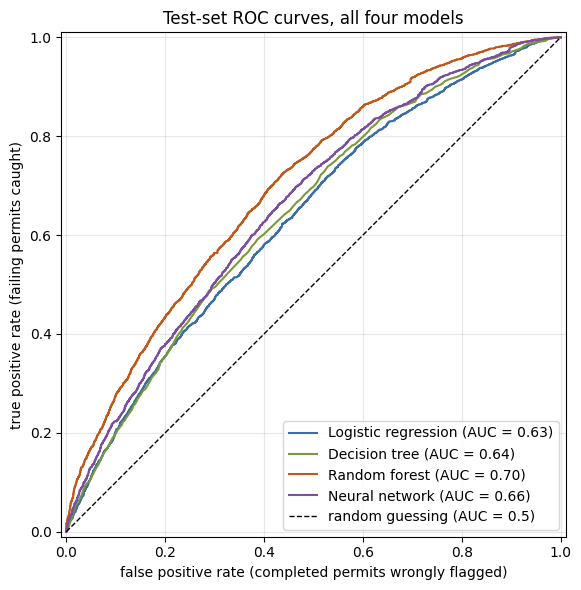

In [12]:
# --- Step 8 — ROC curves ---
fig, ax = plt.subplots(figsize=(6.5, 6))
for (name, p), color in zip(probs.items(), ['#3b6ea5', '#7a9a3a', '#c0581a', '#7b4fa0']):
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=ax, color=color)
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='random guessing (AUC = 0.5)')
ax.set_xlabel('false positive rate (completed permits wrongly flagged)')
ax.set_ylabel('true positive rate (failing permits caught)')
ax.set_title('Test-set ROC curves, all four models'); ax.legend(loc='lower right'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Are the gaps real?** As in `03`, the test permits are resampled 1,000 times (bootstrap) to get a 95% interval for each AUC difference involving the network. An interval that excludes 0 means the gap is not luck.

In [13]:
# --- Step 8 — bootstrap 95% intervals for the network vs. each other model ---
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.to_numpy()
diffs = {f'Network − {m.lower()}': [] for m in ['Logistic regression', 'Decision tree', 'Random forest']}
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    nn = roc_auc_score(yt[i], probs['Neural network'][i])
    for m in ['Logistic regression', 'Decision tree', 'Random forest']:
        diffs[f'Network − {m.lower()}'].append(nn - roc_auc_score(yt[i], probs[m][i]))
pd.DataFrame(diffs).quantile([0.025, 0.5, 0.975]).T.round(3).set_axis(['2.5%', 'median', '97.5%'], axis=1)

,2.5%,median,97.5%
Network − logistic regression,0.020,0.026,0.032
Network − decision tree,0.007,0.014,0.022
Network − random forest,-0.046,-0.039,-0.031


**Reading the intervals:**
- **Network vs. logistic regression:** +0.026 (0.020 to 0.032). The network is **genuinely better**.
- **Network vs. decision tree:** +0.014 (0.007 to 0.022). It is **genuinely better**, but by less.
- **Network vs. random forest:** −0.039 (−0.046 to −0.031). The forest is **genuinely better**, and no interval comes near 0.

*(As in `03`, the bootstrap resamples permits rather than project batches, so the intervals are slightly too narrow. The gaps are large enough that this doesn't change any conclusion.)*

## Step 9 — Using it: flagging the riskiest permits
As in `03`, the practical question for the department is: *if staff can follow up on the riskiest k% of new permits, how many of those really fail?* The table compares the network with the forest on the same test permits. The share of flagged permits that fail, against the 37% average, is what makes the list worth acting on.

In [14]:
# --- Step 9 — review the riskiest k% of test permits ---
rows = []
for k in [0.05, 0.10, 0.20, 0.30]:
    row = {'review the riskiest': f'{k:.0%}'}
    for name in ['Neural network', 'Random forest']:
        pred = (probs[name] >= np.quantile(probs[name], 1 - k)).astype(int)
        row[f'{name}: precision'] = precision_score(y_test, pred)
        row[f'{name}: recall'] = recall_score(y_test, pred)
    rows.append(row)
print(f'Base rate (share of test permits that did not finish): {y_test.mean():.1%}')
pd.DataFrame(rows).set_index('review the riskiest').round(3)

Base rate (share of test permits that did not finish): 36.7%


,Neural network: precision,Neural network: recall,Random forest: precision,Random forest: recall
review the riskiest,,,,
5%,0.630,0.086,0.740,0.101
10%,0.588,0.160,0.650,0.177
20%,0.539,0.293,0.590,0.321
30%,0.511,0.418,0.552,0.451


**Reading the table:** if staff review the riskiest 10% of permits, **59%** of the network's picks really fail, against **65%** of the forest's (base rate 37%). At every list size the forest's list is a few points more accurate and catches a few more failures. The network's list is still useful (1.6× the base rate), but if the department uses one model to rank permits, it should be the forest.

## Step 10 — What drives the network?
A network's weights can't be read like coefficients: each input feeds every hidden neuron, and the effects mix. **Permutation importance** works for any model. Shuffle one feature in the test set, and see how much the AUC drops. Computing it for the network and the forest shows whether they learned the same story.

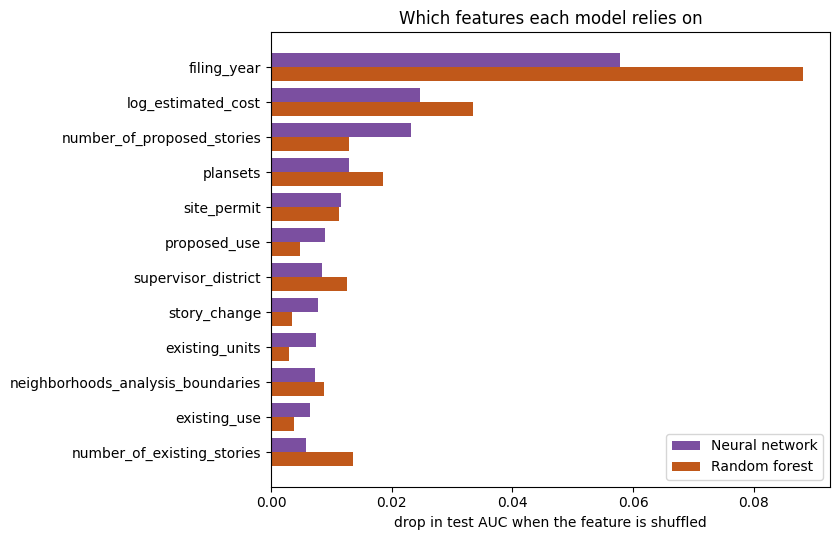

,Neural network: AUC drop,Random forest: AUC drop
filing_year,0.0578,0.0882
log_estimated_cost,0.0247,0.0334
number_of_proposed_stories,0.0232,0.0130
plansets,0.0129,0.0186
site_permit,0.0117,0.0113
proposed_use,0.0090,0.0048
supervisor_district,0.0085,0.0126
story_change,0.0078,0.0035
existing_units,0.0074,0.0030
neighborhoods_analysis_boundaries,0.0073,0.0088


In [15]:
# --- Step 10 — permutation importance, network vs forest ---
imp = {}
for name in ['Neural network', 'Random forest']:
    r = permutation_importance(fitted[name], X_test, y_test, scoring='roc_auc', n_repeats=5,
                               random_state=RANDOM_STATE, n_jobs=-1)
    imp[name] = pd.Series(r.importances_mean, index=X_test.columns)
imp = pd.DataFrame(imp).sort_values('Neural network', ascending=False)
top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
y = np.arange(len(top))
ax.barh(y + 0.2, top['Neural network'], height=0.4, color='#7b4fa0', label='Neural network')
ax.barh(y - 0.2, top['Random forest'], height=0.4, color='#c0581a', label='Random forest')
ax.set_yticks(y); ax.set_yticklabels(top.index); ax.legend()
ax.set_xlabel('drop in test AUC when the feature is shuffled')
ax.set_title('Which features each model relies on')
plt.tight_layout(); plt.show()
imp.round(4).rename(columns=lambda c: f'{c}: AUC drop')

**Reading the comparison:** the network and the forest learned **the same story**. Both put `filing_year` first by a wide margin and estimated cost second. Number of plan sets and number of stories come next in both, followed by site permits, location and building use. The network relies a bit more on building use and size changes (`proposed_use`, `story_change`), and less on filing year, than the forest.

Two models built in completely different ways agreeing on what matters makes the finding more trustworthy. It also means the network carries the **same filing-year limitation** found in `03`: much of its signal is "when was it filed", which won't transfer cleanly to permits filed today.

## Step 11 — Conclusions and design choices recap

In [16]:
# --- Step 11 — summary for the report ---
summary = results.loc[list(models), ['test ROC AUC', 'error rate', 'precision', 'recall', 'seconds to fit']].copy()
summary['interpretable?'] = ['yes: one odds ratio per feature', 'yes: a flowchart of rules',
                             'partly: importance only', 'partly: importance only']
summary

,test ROC AUC,error rate,precision,recall,seconds to fit,interpretable?
model,,,,,,
Logistic regression,0.633,0.415,0.452,0.605,0.601,yes: one odds ratio per feature
Decision tree,0.644,0.361,0.519,0.248,0.593,yes: a flowchart of rules
Random forest,0.698,0.331,0.588,0.335,14.775,partly: importance only
Neural network,0.659,0.352,0.538,0.303,1.958,partly: importance only


### What we found
1. **The tuned network (one hidden layer of 64 neurons, `alpha = 0.1`) reaches a test AUC of 0.659.** It beats logistic regression (0.633) and the decision tree (0.644), and the bootstrap confirms both gaps are real.
2. **It does not beat the random forest (0.698).** The forest's lead is about 0.04 AUC and clearly outside the noise.
3. **The network and the forest agree on what drives risk:** filing year, cost, building size and plan sets.

### Why the forest still wins on this data
This is a common result for **tabular data**: a few dozen mixed numeric and categorical columns, many of them one-hot. Trees split directly on "is this category present?" and on thresholds such as "filed before 2003". A network has to approximate those sharp jumps with smooth curves, and its extra flexibility is spent fighting overfitting (Steps 3 and 5). Networks shine on images, sound and text, where there are thousands of raw inputs to combine in stages. Ours is not that kind of problem.

### Design choices recap

| Choice | Decision | Evidence in this notebook |
|---|---|---|
| Input scaling | Standardize | Without it, CV AUC drops from 0.662 to 0.603 (Step 2) |
| Depth | One hidden layer | Two layers never beat one; the largest network was the worst (Step 5) |
| Width | 64 neurons | Ties with 128; the smaller network is preferred |
| Weight decay | `alpha = 0.1` | Inside the tested range: less overfits, `1.0` underfits (Steps 3 and 5) |
| Training length | Early stopping (patience 10) | Validation AUC peaks long before training AUC stops rising (Step 3) |
| Optimiser and learning rate | Adam, 0.001, batches of 256 | Defaults were best; fast rates with small batches hurt (Step 6) |
| Random seed | Fixed at 42 | Seed spread is 0.003 AUC, too small to change any ranking (Step 7) |
| Class imbalance | No reweighting | AUC is unaffected; staff capacity sets the cutoff (Step 9) |

### Answer to the question
Same as `03`: application details predict failure **better than chance but modestly**. A neural network confirms the signal is partly non-linear (it beats logistic regression), but it doesn't find anything the random forest missed. **Recommendation:** use the random forest for the ranked list of risky permits. The network adds no accuracy and is just as hard to explain, so it has no advantage for the department.

### Limitations
- **Filing year** carries much of the signal for every model (see `03`, Step 9).
- **Early stopping** uses scikit-learn's random 10% of rows, not grouped batches, so the stopping point is slightly noisy.
- **Grid search** covers the main hyperparameters but not every option, for example dropout or batch normalisation, which `MLPClassifier` doesn't offer. Given how flat the scores are across settings (0.655–0.666 for most of round 1), a wider search is unlikely to close a 0.04 gap.